In [8]:
import os
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix

In [9]:
# أولاً: شوف إيه الفايلات الموجودة
print(os.listdir("."))

['.config', '354861_6a07167d47fb9_1778849405.zip', 'sample_data']


In [10]:
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {DEVICE}")

✅ Using device: cpu


In [13]:
DATA_DIR = "/content/fruits_dataset"

In [14]:
zip_name = "354861_6a07167d47fb9_1778849405.zip"  # اسم الـ zip اللي رفعته
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall(".")

# شوف الفولدرات دلوقتي
print(os.listdir("."))

['.config', '354861_6a07167d47fb9_1778849405.zip', 'fruits_dataset', 'sample_data']


In [15]:
print("\n" + "="*50)
print("📊 DATASET INSPECTION")
print("="*50)

classes = sorted(os.listdir(DATA_DIR))
print(f"Classes found: {classes}")

total = 0
for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    files = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    print(f"  {cls:10s}: {len(files):4d} images")
    total += len(files)
print(f"  {'TOTAL':10s}: {total:4d} images")


📊 DATASET INSPECTION
Classes found: ['apple', 'banana', 'orange']
  apple     :  100 images
  banana    :  100 images
  orange    :  100 images
  TOTAL     :  300 images


In [16]:
print("\n🔍 Checking image formats and sizes...")
sizes = []
modes = []
formats_found = set()
corrupt = []

for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_path):
        fpath = os.path.join(cls_path, fname)
        try:
            with Image.open(fpath) as img:
                sizes.append(img.size)
                modes.append(img.mode)
                formats_found.add(img.format)
        except Exception as e:
            corrupt.append(fpath)

size_counts = Counter(sizes)
mode_counts = Counter(modes)

print(f"  Image formats  : {formats_found}")
print(f"  Color modes    : {dict(mode_counts)}")
print(f"  Unique sizes   : {len(size_counts)} different sizes")
print(f"  Most common sz : {size_counts.most_common(3)}")
print(f"  Corrupt files  : {len(corrupt)}")
if corrupt:
    print(f"  ⚠️  Corrupt: {corrupt}")
else:
    print("  ✅ All images are valid!")

# Convert any non-RGB images to RGB (needed before training)
non_rgb = [m for m in modes if m != 'RGB']
if non_rgb:
    print(f"\n⚠️  Found non-RGB images: {Counter(non_rgb)} — will convert in transforms")
else:
    print("  ✅ All images are RGB")



🔍 Checking image formats and sizes...
  Image formats  : {'JPEG', 'PNG'}
  Color modes    : {'RGB': 217, 'P': 83}
  Unique sizes   : 8 different sizes
  Most common sz : [((1201, 710), 50), ((200, 200), 50), ((800, 797), 34)]
  Corrupt files  : 0
  ✅ All images are valid!

⚠️  Found non-RGB images: Counter({'P': 83}) — will convert in transforms



📸 Showing sample images...


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


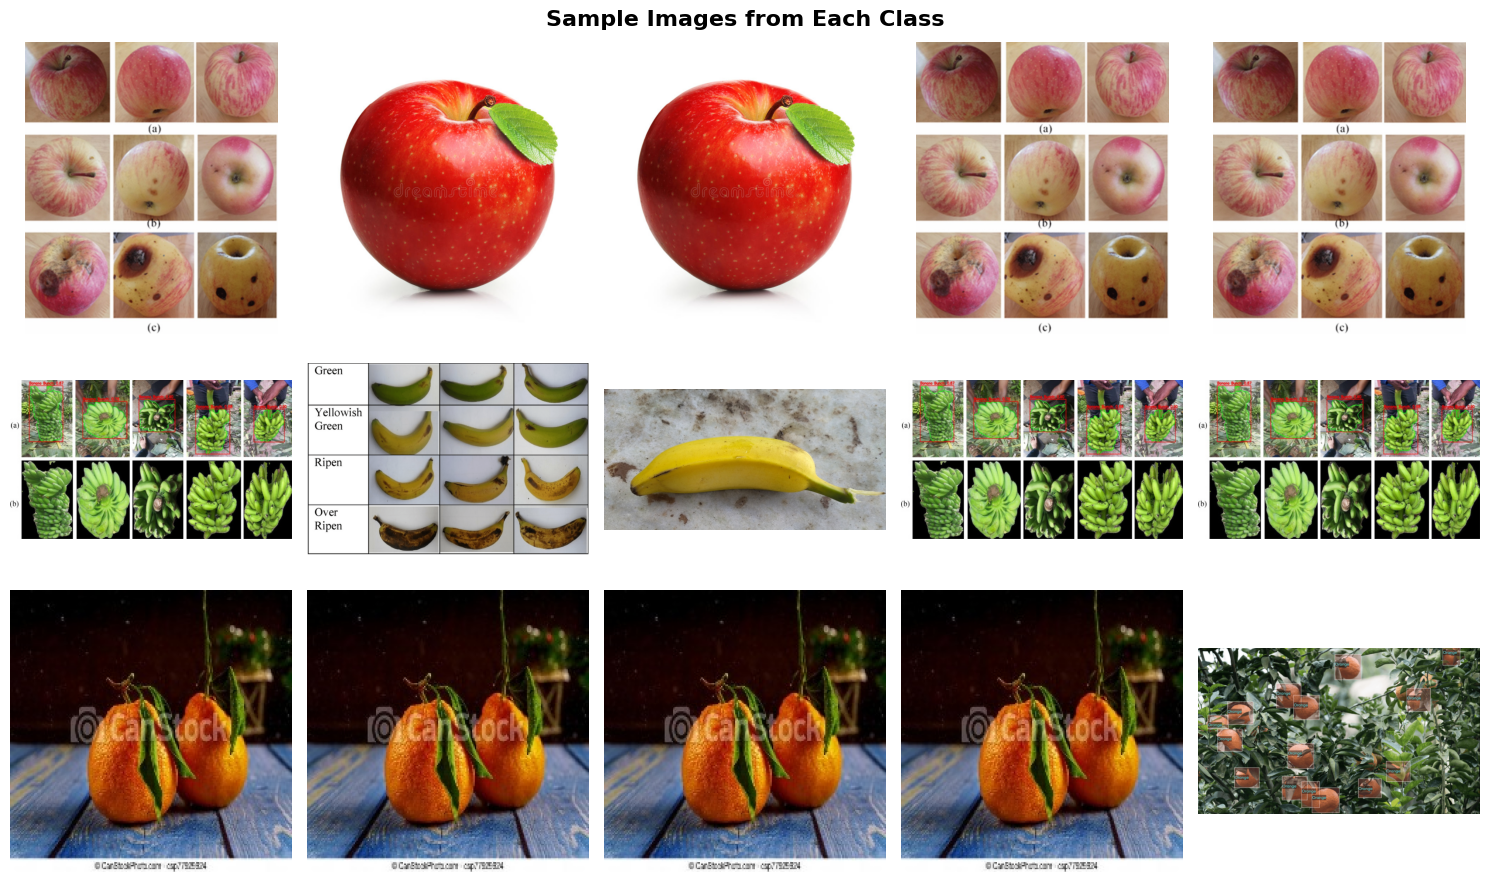

✅ Sample images saved as sample_images.png


In [17]:
print("\n📸 Showing sample images...")

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
fig.suptitle("Sample Images from Each Class", fontsize=16, fontweight='bold')

for row, cls in enumerate(classes):
    cls_path = os.path.join(DATA_DIR, cls)
    img_files = random.sample(os.listdir(cls_path), 5)
    for col, fname in enumerate(img_files):
        img = Image.open(os.path.join(cls_path, fname)).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(cls.capitalize(), fontsize=13, fontweight='bold', rotation=0, labelpad=60)

plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Sample images saved as sample_images.png")

In [18]:
IMG_SIZE   = 224
MEAN       = [0.485, 0.456, 0.406]   # ImageNet mean
STD        = [0.229, 0.224, 0.225]   # ImageNet std

# Training: augmentation to fight overfitting
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomGrayscale(p=0.05),        # rare grayscale augment
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

In [19]:
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

In [20]:
full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=train_transforms)
CLASS_NAMES  = full_dataset.classes
NUM_CLASSES  = len(CLASS_NAMES)
print(f"\n✅ Classes detected by ImageFolder: {CLASS_NAMES}")

n       = len(full_dataset)
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
n_test  = n - n_train - n_val

train_set, val_set, test_set = random_split(full_dataset, [n_train, n_val, n_test])


✅ Classes detected by ImageFolder: ['apple', 'banana', 'orange']


In [21]:
val_set.dataset  = datasets.ImageFolder(root=DATA_DIR, transform=val_transforms)
test_set.dataset = datasets.ImageFolder(root=DATA_DIR, transform=val_transforms)

print(f"  Train : {len(train_set)} images")
print(f"  Val   : {len(val_set)}   images")
print(f"  Test  : {len(test_set)}  images")

BATCH_SIZE = 16
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


  Train : 210 images
  Val   : 45   images
  Test  : 45  images


In [22]:
print("\n🏗️  Building ResNet18 Transfer Learning model...")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers first (feature extractor)
for param in model.parameters():
    param.requires_grad = False

# Add Dropout to reduce overfitting
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(256, NUM_CLASSES)
)



🏗️  Building ResNet18 Transfer Learning model...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 57.8MB/s]


In [23]:
# Unfreeze layer4 + fc for fine-tuning (best accuracy strategy)
for param in model.layer4.parameters():
    param.requires_grad = True
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"  Total params    : {total_params:,}")
print(f"  Trainable params: {trainable:,}  ({100*trainable/total_params:.1f}%)")

  Total params    : 11,308,611
  Trainable params: 8,525,827  (75.4%)


In [24]:
EPOCHS    = 20
LR        = 1e-3

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)   # label smoothing → less overfit

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=1e-4
)

# CosineAnnealing: gradually reduces LR → better convergence
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

In [25]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total   += labels.size(0)
    return running_loss / total, 100. * correct / total


def eval_epoch(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total   += labels.size(0)
    return running_loss / total, 100. * correct / total

In [26]:
print(f"\n🚀 Training for {EPOCHS} epochs on {DEVICE}...\n")
print(f"{'Epoch':>6}  {'Train Loss':>10}  {'Train Acc':>9}  {'Val Loss':>8}  {'Val Acc':>7}  {'LR':>10}")
print("-" * 62)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0
best_model_path = "best_fruit_model.pth"
patience, no_improve = 5, 0


🚀 Training for 20 epochs on cpu...

 Epoch  Train Loss  Train Acc  Val Loss  Val Acc          LR
--------------------------------------------------------------


In [27]:
for epoch in range(1, EPOCHS + 1):
    t_loss, t_acc = train_epoch(model, train_loader, optimizer, criterion)
    v_loss, v_acc = eval_epoch(model, val_loader, criterion)
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(t_loss)
    history['train_acc'].append(t_acc)
    history['val_loss'].append(v_loss)
    history['val_acc'].append(v_acc)

    marker = ""
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        torch.save(model.state_dict(), best_model_path)
        marker = " ✅ best"
        no_improve = 0
    else:
        no_improve += 1

    print(f"{epoch:>6}  {t_loss:>10.4f}  {t_acc:>8.2f}%  {v_loss:>8.4f}  {v_acc:>6.2f}%  {current_lr:>10.2e}{marker}")

    if no_improve >= patience:
        print(f"\n⏹️  Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
        break

print(f"\n🏆 Best Validation Accuracy: {best_val_acc:.2f}%")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


     1      0.4876     92.38%    0.6507  100.00%    9.94e-04 ✅ best
     2      0.3604     99.05%    0.4441  100.00%    9.76e-04
     3      0.3889     98.10%    0.4290  100.00%    9.46e-04
     4      0.3457    100.00%    0.3572  100.00%    9.05e-04
     5      0.3324     99.52%    0.3231  100.00%    8.54e-04
     6      0.3602     98.57%    0.3333  100.00%    7.94e-04

⏹️  Early stopping at epoch 6 (no improvement for 5 epochs)

🏆 Best Validation Accuracy: 100.00%


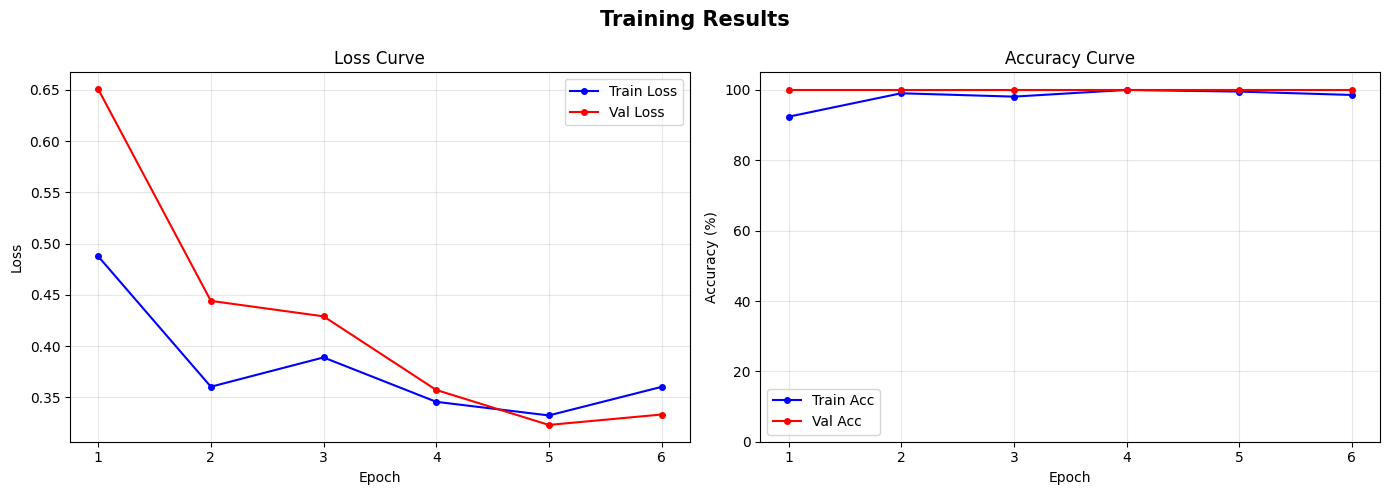

✅ Training curves saved as training_curves.png


In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training Results", fontsize=15, fontweight='bold')

eps = range(1, len(history['train_loss']) + 1)

ax1.plot(eps, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
ax1.plot(eps, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curve'); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(eps, history['train_acc'], 'b-o', label='Train Acc', markersize=4)
ax2.plot(eps, history['val_acc'],   'r-o', label='Val Acc',   markersize=4)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Accuracy Curve'); ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_ylim([0, 105])

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training curves saved as training_curves.png")


In [29]:
print("\n" + "="*50)
print("🧪 FINAL EVALUATION ON TEST SET")
print("="*50)

# Load best checkpoint
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

test_acc = 100. * np.mean(np.array(all_preds) == np.array(all_labels))
print(f"\n✅ Test Accuracy: {test_acc:.2f}%\n")

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))


🧪 FINAL EVALUATION ON TEST SET

✅ Test Accuracy: 100.00%

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        21
      banana       1.00      1.00      1.00        12
      orange       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



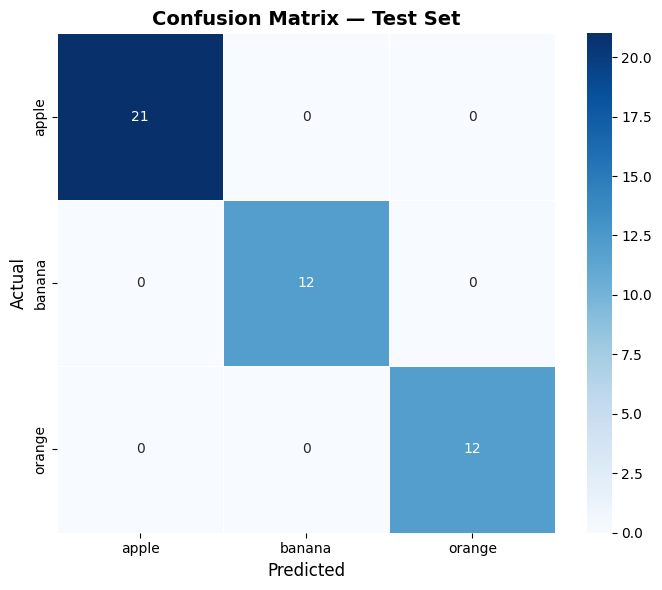

✅ Confusion matrix saved as confusion_matrix.png


In [30]:
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual',    fontsize=12)
ax.set_title('Confusion Matrix — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved as confusion_matrix.png")

In [31]:
def predict_image(img_path: str, model, class_names: list):
    """Predict the class of a single image and show it."""
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ])
    img = Image.open(img_path).convert("RGB")
    tensor = transform(img).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        outputs = model(tensor)
        probs   = torch.softmax(outputs, dim=1)[0]
        pred_idx = probs.argmax().item()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.imshow(img); ax1.axis('off')
    ax1.set_title(f"Predicted: {class_names[pred_idx].upper()}\n({probs[pred_idx]*100:.1f}%)",
                  fontsize=14, fontweight='bold', color='green')
    colors = ['#2ecc71' if i == pred_idx else '#bdc3c7' for i in range(len(class_names))]
    ax2.barh(class_names, probs.cpu().numpy() * 100, color=colors)
    ax2.set_xlabel('Confidence (%)')
    ax2.set_title('Class Probabilities'); ax2.set_xlim([0, 100])
    plt.tight_layout(); plt.show()
    return class_names[pred_idx], probs.cpu().numpy()


🎯 Demo prediction on: /content/fruits_dataset/banana/banana_75.jpg


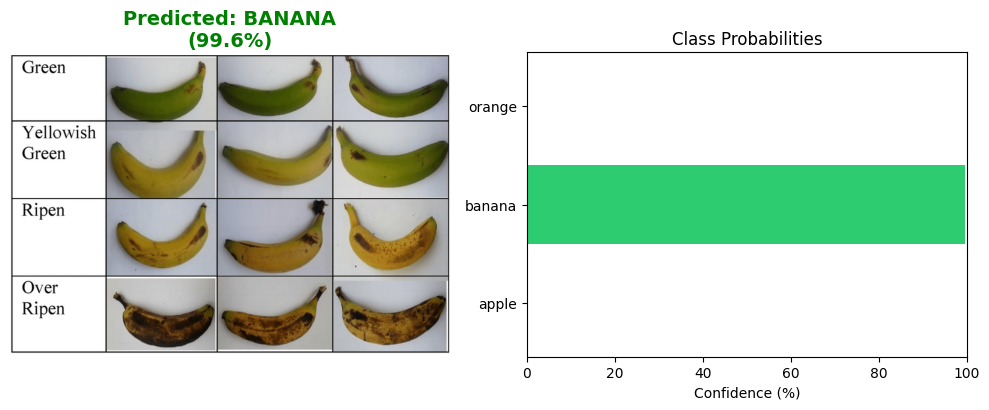

   Actual: banana  |  Predicted: banana


In [32]:
sample_class = random.choice(CLASS_NAMES)
sample_dir   = os.path.join(DATA_DIR, sample_class)
sample_img   = os.path.join(sample_dir, random.choice(os.listdir(sample_dir)))
print(f"\n🎯 Demo prediction on: {sample_img}")
predicted, confidences = predict_image(sample_img, model, CLASS_NAMES)
print(f"   Actual: {sample_class}  |  Predicted: {predicted}")

In [33]:
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': CLASS_NAMES,
    'test_accuracy': test_acc,
    'val_accuracy': best_val_acc,
}, "fruit_classifier_final.pth")

print("\n" + "="*50)
print("🎉 DONE!")
print(f"   Best Val Accuracy : {best_val_acc:.2f}%")
print(f"   Test Accuracy     : {test_acc:.2f}%")
print("   Saved: fruit_classifier_final.pth")
print("   Saved: best_fruit_model.pth")
print("="*50)


🎉 DONE!
   Best Val Accuracy : 100.00%
   Test Accuracy     : 100.00%
   Saved: fruit_classifier_final.pth
   Saved: best_fruit_model.pth
